# Card-Pair Activity for Transaction Fraud Detection

Does recent activity on the same card pair help catch more fraud at a fixed review capacity? This project uses the IEEE-CIS Fraud Detection dataset to build a feature that counts prior transactions linked to the same `(card1, card2)` pair within seven days. It compares CatBoost models with and without the feature, then tests whether the gain holds across chronological validation windows.

---

## 1. Load and Inspect the Data

Load the identity CSV in Colab and inspect its rows and columns before profiling the card fields in the transaction data.


In [ ]:
# from google.colab import drive  # only needed on Colab
import polars as pl

# # 1. Mount Google Drive
# drive.mount('/content/drive')

# 2. Specify the path to your CSV file
# Replace 'your_folder/your_file.csv' with the actual path in your Google Drive
csv_path = './drive/MyDrive/Colab Notebooks/train_identity.csv'

# 3. Read the CSV using Polars
df = pl.read_csv(csv_path)
df.head()

In [9]:
for col in df.columns:
  print(col,end=',')

TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,id_10,id_11,id_12,id_13,id_14,id_15,id_16,id_17,id_18,id_19,id_20,id_21,id_22,id_23,id_24,id_25,id_26,id_27,id_28,id_29,id_30,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo,

---

## 2. Profile the Card-Pair Key

Measure how often both card fields are available, how many transactions share a pair, and how large those groups get.


In [13]:
# %% Section 2 — Profile the candidate graph key: (card1, card2)
# Description: Measure key coverage, how often transactions share the same key,
# and how large those groups get before deciding how to construct graph edges.

from pathlib import Path

import polars as pl

# from google.colab import drive
# drive.mount("/content/drive")
DATA_DIR = Path("/content/drive/MyDrive/Colab Notebooks/data")

TRAIN_CSV = DATA_DIR / "train_transaction.csv"  # Match the actual filename.
KEY_COLS = ["card1", "card2"]

tx = pl.read_csv(
    TRAIN_CSV,
    columns=["TransactionID", "TransactionDT", *KEY_COLS],
)

# Both fields must be present to assign a transaction to a key.
linked = tx.drop_nulls(subset=KEY_COLS)

group_sizes = (
    linked.group_by(KEY_COLS)
    .agg(pl.len().alias("n_transactions"))
)

# A group of size 2 or more gives each transaction at least one neighbor
# in the full dataset, before we apply any time filter.
n_with_neighbors = (
    group_sizes
    .filter(pl.col("n_transactions") > 1)
    .get_column("n_transactions")
    .sum()
)

print(f"Total transactions:          {tx.height:,}")
print(f"Complete key:                {linked.height:,} ({linked.height / tx.height:.1%})")
print(f"Distinct keys:               {group_sizes.height:,}")
print(
    f"Transactions with neighbors: {n_with_neighbors:,} "
    f"({n_with_neighbors / tx.height:.1%} of all transactions)"
)

size = pl.col("n_transactions")

print("\nTransactions per key:")
display(group_sizes.select(
    size.median().alias("p50"),
    size.quantile(0.90, interpolation="linear").alias("p90"),
    size.quantile(0.99, interpolation="linear").alias("p99"),
    size.max().alias("max"),
))

print("\nFive largest key groups:")
display(group_sizes.sort("n_transactions", descending=True).head(5))

Total transactions:          590,540
Complete key:                581,607 (98.5%)
Distinct keys:               13,490
Transactions with neighbors: 578,178 (97.9% of all transactions)

Transactions per key:


p50,p90,p99,max
f64,f64,f64,u32
4.0,45.0,754.44,14891



Five largest key groups:


card1,card2,n_transactions
i64,f64,u32
7919,194.0,14891
9500,321.0,14112
15885,545.0,10332
17188,321.0,10312
15066,170.0,7918


---

### 2B. Compare Alternative Card Keys

Check how adding card fields changes key coverage, the share of transactions that can be linked, and the largest group sizes.


In [16]:
# %% Section 2B — Compare candidate card grouping keys
# Description: Measure how each additional card field affects key coverage,
# transaction connectivity, and the size of the largest groups.

card_cols = [f"card{i}" for i in range(1, 7)]
cards = pl.read_csv(TRAIN_CSV, columns=card_cols)

base = ["card1", "card2"]
candidates = [
    ["card1"],
    base,
    *[base + [col] for col in card_cols[2:]],
    card_cols,
]

results = []

for cols in candidates:
    complete = cards.drop_nulls(subset=cols)
    sizes = complete.group_by(cols).len().get_column("len")
    n_linked = sizes.filter(sizes > 1).sum()

    results.append({
        "grouping_key": " + ".join(cols),
        "coverage_pct": round(100 * complete.height / cards.height, 2),
        "with_neighbors_pct": round(100 * n_linked / cards.height, 2),
        "n_groups": len(sizes),
        "p50_group_size": sizes.median(),
        "p99_group_size": sizes.quantile(0.99, interpolation="linear"),
        "largest_group": sizes.max(),
    })

with pl.Config(tbl_rows=-1, tbl_cols=-1):
    display(pl.DataFrame(results))

grouping_key,coverage_pct,with_neighbors_pct,n_groups,p50_group_size,p99_group_size,largest_group
str,f64,f64,i64,f64,f64,i64
"""card1""",100.0,99.42,13553,4.0,786.44,14932
"""card1 + card2""",98.49,97.91,13490,4.0,754.44,14891
"""card1 + card2 + card3""",98.49,97.91,13497,4.0,754.16,14891
"""card1 + card2 + card4""",98.49,97.91,13481,4.0,754.8,14891
"""card1 + card2 + card5""",98.13,97.54,13653,4.0,736.56,14112
"""card1 + card2 + card6""",98.49,97.9,13569,4.0,752.64,14891
"""card1 + card2 + card3 + card4 …",98.13,97.54,13691,4.0,728.2,14112


---

## 3. Build a Bipartite Graph

Use NetworkX to connect example transactions to a shared card-pair node. Follow two edges from a target transaction to find other transactions and count the ones in its prior seven-day window.


In [19]:
# %% Section 3 — Build a bipartite graph and count historical neighbors
# Description: Build a four-transaction graph, traverse two edges from
# a target transaction, and count only neighbors from the prior seven days.

import networkx as nx

KEY_COLS = ["card1", "card2"]
WINDOW_SECONDS = 7 * 24 * 60 * 60

graph_tx = tx.drop_nulls(
    subset=["TransactionID", "TransactionDT", *KEY_COLS]
)

# Pick a group where the expected answer can be checked by hand.
example_key = (
    graph_tx.group_by(KEY_COLS)
    .agg(
        pl.len().alias("n_transactions"),
        pl.col("TransactionDT").n_unique().alias("n_distinct_times"),
        (pl.col("TransactionDT").max() - pl.col("TransactionDT").min())
        .alias("span_seconds"),
    )
    .filter(
        (pl.col("n_transactions") == 4)
        & (pl.col("n_distinct_times") == 4)
        & (pl.col("span_seconds") <= WINDOW_SECONDS)
    )
    .select(KEY_COLS)
    .sort(KEY_COLS)
    .head(1)
)

example = graph_tx.join(example_key, on=KEY_COLS).sort("TransactionDT")
display(example)

TransactionID,TransactionDT,card1,card2
i64,i64,i64,f64
3328295,8396098,1058,555.0
3329596,8449729,1058,555.0
3330518,8464559,1058,555.0
3330554,8465032,1058,555.0


In [35]:
# Two node types: individual transactions and one shared card-attribute pair.
G = nx.Graph()
card_node = ("card12_pair", *example_key.row(0))
G.add_node(card_node, bipartite=1)
for row in example.iter_rows(named=True):
    tx_node = ("transaction", row["TransactionID"])
    G.add_node(tx_node, bipartite=0, trans_time=row["TransactionDT"])
    G.add_edge(tx_node, card_node)
# A path length of 2 means crossing exactly two edges.
target = ("transaction", example["TransactionID"][2])
target_time = G.nodes[target]["trans_time"]
# target, target_time
distances = nx.single_source_shortest_path_length(G, target, cutoff=2)
two_hop_nodes = [node for node, distance in distances.items() if distance == 2]
# two_hop_nodes
historical_neighbors = [
    node
    for node in two_hop_nodes
    if target_time - WINDOW_SECONDS <= G.nodes[node]["trans_time"] < target_time
]
# historical_neighbors
print(f"Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
print(f"Target transaction: {target[1]}")
print(f"All two-hop neighbors: {[node[1] for node in two_hop_nodes]}")
print(f"Prior 7-day neighbors: {[node[1] for node in historical_neighbors]}")
print(f"Feature value: {len(historical_neighbors)}")

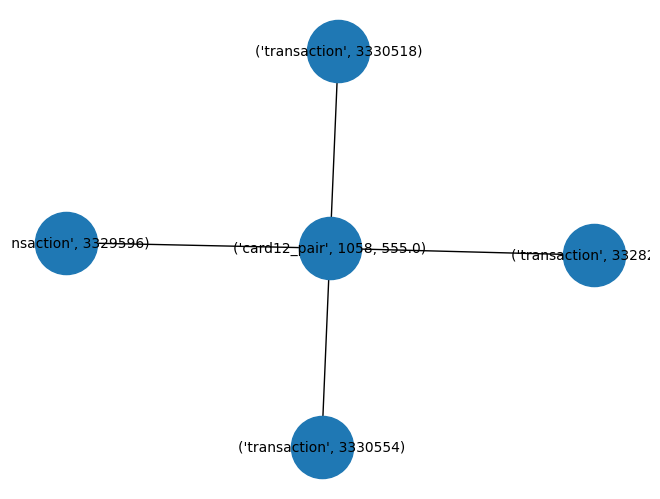

In [36]:
import matplotlib.pyplot as plt

nx.draw(G, with_labels=True, node_size=2000, font_size=10)
plt.show()

---

## 4. Compute Historical Neighbor Counts

Scale the count to the transaction dataset and verify that the seven-day window includes its lower boundary and excludes events at the target timestamp.


In [43]:
# %% Section 4 — Compute prior 7-day two-hop neighbor counts
# Description: Scale the NetworkX example to the full training set by
# counting earlier transactions within each card pair. Verify the time
# boundaries and compare the result with the Section 3 example.

import numpy as np

FEATURE = "prior_7d_card_pair_neighbors"

def count_prior_neighbors(sorted_times, window_seconds):
    """Count events in [t - window_seconds, t) for every event at t."""
    window_start = np.searchsorted(
        sorted_times, sorted_times - window_seconds, side="left"
    )
    window_end = np.searchsorted(sorted_times, sorted_times, side="left")
    return window_end - window_start

# At t = 7 days + 1 second:
# t=0 is too old, t=1 is exactly on the lower boundary,
# and both events at the target second are excluded.
test_times = np.array([0, 1, WINDOW_SECONDS + 1, WINDOW_SECONDS + 1])
assert count_prior_neighbors(test_times, WINDOW_SECONDS).tolist() == [0, 1, 1, 1]

feature_groups = []

for group in graph_tx.partition_by(KEY_COLS):
    group = group.sort("TransactionDT")
    times = group["TransactionDT"].to_numpy()
    counts = count_prior_neighbors(times, WINDOW_SECONDS)

    feature_groups.append(
        group.select("TransactionID").with_columns(pl.Series(FEATURE, counts))
    )

features = pl.concat(feature_groups)
tx_features = tx.join(features, on="TransactionID", how="left", validate="1:1")

# Cross-check the full-table calculation against the hand-checked graph.
target_check = tx_features.filter(pl.col("TransactionID") == target[1])
assert target_check[FEATURE].item() == len(historical_neighbors)

print("Section 3 cross-check passed.")
display(target_check.select("TransactionID", "TransactionDT", FEATURE))

display(tx_features.select(
    pl.len().alias("n_transactions"),
    pl.col(FEATURE).null_count().alias("n_missing"),
    (pl.col(FEATURE) == 0).sum().alias("n_zero"),
    (pl.col(FEATURE) > 0).sum().alias("n_positive"),
    pl.col(FEATURE).median().alias("p50"),
    pl.col(FEATURE).quantile(0.99).alias("p99"),
    pl.col(FEATURE).max().alias("max"),
))

Section 3 cross-check passed.


TransactionID,TransactionDT,prior_7d_card_pair_neighbors
i64,i64,i64
3330518,8464559,2


n_transactions,n_missing,n_zero,n_positive,p50,p99,max
u32,u32,u32,u32,f64,f64,i64
590540,8933,48469,533138,34.0,957.0,1678


---

## 5. Compare Fraud Rates Across Time

Join the fraud labels and compare fraud rates across the same neighbor-count buckets in the earlier and later periods.


In [44]:
# %% Section 5 — Compare fraud rates by historical neighbor count
# Description: Join fraud labels, split transactions chronologically,
# and compare fraud rates across the same feature buckets in both periods.

labels = pl.read_csv(TRAIN_CSV, columns=["TransactionID", "isFraud"])
analysis_df = tx_features.join(labels, on="TransactionID", validate="1:1")

cutoff = analysis_df["TransactionDT"].quantile(0.80)
neighbor_count = pl.col(FEATURE)

analysis_df = analysis_df.with_columns(
    pl.when(pl.col("TransactionDT") < cutoff)
    .then(pl.lit("Earlier"))
    .otherwise(pl.lit("Later"))
    .alias("period"),
    pl.when(neighbor_count.is_null()).then(pl.lit("Missing"))
    .when(neighbor_count == 0).then(pl.lit("0"))
    .when(neighbor_count <= 10).then(pl.lit("1–10"))
    .when(neighbor_count <= 50).then(pl.lit("11–50"))
    .when(neighbor_count <= 200).then(pl.lit("51–200"))
    .otherwise(pl.lit("201+"))
    .alias("neighbor_bucket"),
)

period_summary = analysis_df.group_by("period").agg(
    pl.len().alias("n_transactions"),
    (pl.col("isFraud").mean() * 100).alias("period_fraud_rate_pct"),
)

bucket_order = ["Missing", "0", "1–10", "11–50", "51–200", "201+"]

bucket_summary = (
    analysis_df.group_by("period", "neighbor_bucket")
    .agg(
        pl.len().alias("n_transactions"),
        pl.col("isFraud").sum().alias("n_fraud"),
        (pl.col("isFraud").mean() * 100).round(2).alias("fraud_rate_pct"),
    )
    .with_columns(pl.col("neighbor_bucket").cast(pl.Enum(bucket_order)))
    .sort("period", "neighbor_bucket")
)

display(period_summary.sort("period"))
with pl.Config(tbl_rows=-1):
    display(bucket_summary)

period,n_transactions,period_fraud_rate_pct
str,u32,f64
"""Earlier""",472431,3.513529
"""Later""",118109,3.440889


period,neighbor_bucket,n_transactions,n_fraud,fraud_rate_pct
str,enum,u32,i64,f64
"""Earlier""","""Missing""",7025,393,5.59
"""Earlier""","""0""",38673,837,2.16
"""Earlier""","""1–10""",114260,3701,3.24
"""Earlier""","""11–50""",111586,4851,4.35
"""Earlier""","""51–200""",121998,4514,3.7
"""Earlier""","""201+""",78889,2303,2.92
"""Later""","""Missing""",1908,30,1.57
"""Later""","""0""",9796,244,2.49
"""Later""","""1–10""",29151,957,3.28


---

## 6. Test Incremental Model Performance

Train CatBoost on the earlier period with and without the graph feature. Compare average precision and fraud capture at the same review capacity on the later period.


In [46]:
%pip install -q catboost

In [47]:
# %% Section 6 — Measure incremental lift from the graph feature
# Description: Train two CatBoost models on the earlier period, then
# compare ranking performance and fraud capture on the same later period.

import numpy as np
from catboost import CatBoostClassifier
from sklearn.metrics import average_precision_score

CARD_COLS = [f"card{i}" for i in range(1, 7)]
CAT_COLS = ["ProductCD", *CARD_COLS]
BASE_COLS = ["TransactionAmt", *CAT_COLS]

# Reuse the Section 5 split and labels. Read the baseline inputs separately.
baseline_data = pl.read_csv(
    TRAIN_CSV,
    columns=["TransactionID", *BASE_COLS],
)

model_df = (
    analysis_df.select("TransactionID", "period", "isFraud", FEATURE)
    .join(baseline_data, on="TransactionID", validate="1:1")
    .with_columns(
        pl.col(CAT_COLS).cast(pl.String).fill_null("__MISSING__")
    )
    .sort("TransactionID")
)

assert model_df.height == analysis_df.height, "Unexpected rows lost in the join"

train_df = model_df.filter(pl.col("period") == "Earlier")
valid_df = model_df.filter(pl.col("period") == "Later")

y_train = train_df["isFraud"].to_numpy()
y_valid = valid_df["isFraud"].to_numpy()

# Both models get the same review budget: the top 1% of Later transactions.
review_count = max(1, int(0.01 * valid_df.height))
total_fraud = int(y_valid.sum())

feature_sets = {
    "Baseline": BASE_COLS,
    "Baseline + graph": [*BASE_COLS, FEATURE],
}

results = []

for name, columns in feature_sets.items():
    X_train = train_df.select(columns).to_pandas()
    X_valid = valid_df.select(columns).to_pandas()

    model = CatBoostClassifier(
        iterations=300,
        depth=6,
        learning_rate=0.1,
        loss_function="Logloss",
        cat_features=CAT_COLS,
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
    )
    model.fit(X_train, y_train)

    scores = model.predict_proba(X_valid)[:, 1]

    # Stable ranking gives tied scores the same TransactionID-based tie-break.
    flagged = np.argsort(-scores, kind="stable")[:review_count]
    fraud_caught = int(y_valid[flagged].sum())

    results.append({
        "model": name,
        "average_precision": average_precision_score(y_valid, scores),
        "reviewed": review_count,
        "fraud_caught": fraud_caught,
        "review_precision_pct": 100 * fraud_caught / review_count,
        "fraud_recall_pct": 100 * fraud_caught / total_fraud,
    })

display(pl.DataFrame(results))

extra_caught = results[1]["fraud_caught"] - results[0]["fraud_caught"]
print(f"Additional fraud cases caught at the same budget: {extra_caught:+,}")

model,average_precision,reviewed,fraud_caught,review_precision_pct,fraud_recall_pct
str,f64,i64,i64,f64,f64
"""Baseline""",0.195281,1181,423,35.817104,10.408465
"""Baseline + graph""",0.20277,1181,448,37.933954,11.023622


Additional fraud cases caught at the same budget: +25


---

## 7. Backtest Across Time Windows

Repeat the model comparison across three chronological validation windows. Measure the change in average precision and the number of frauds caught in the top 1% of scores.


In [48]:
# %% Section 7 — Backtest graph feature lift across time windows
# Description: Repeat the same CatBoost comparison on three historical
# validation windows. Report average precision and fraud captured at top 1%.

event_times = analysis_df.select("TransactionID", "TransactionDT")
backtest_df = model_df.join(
    event_times, on="TransactionID", validate="1:1"
).drop_nulls("TransactionDT").sort("TransactionDT", "TransactionID")

rows = []

for start_q, end_q in [(0.40, 0.50), (0.50, 0.60), (0.60, 0.70)]:
    start = backtest_df["TransactionDT"].quantile(start_q)
    end = backtest_df["TransactionDT"].quantile(end_q)

    fit = backtest_df.filter(pl.col("TransactionDT") < start)
    check = backtest_df.filter(
        (pl.col("TransactionDT") >= start) & (pl.col("TransactionDT") < end)
    )

    fit_y = fit["isFraud"].to_numpy()
    check_y = check["isFraud"].to_numpy()
    review_count = max(1, int(0.01 * check.height))

    scores_by_model = {}

    for name, columns in feature_sets.items():
        model = CatBoostClassifier(
            iterations=300,
            depth=6,
            learning_rate=0.1,
            loss_function="Logloss",
            cat_features=CAT_COLS,
            random_seed=42,
            verbose=False,
            allow_writing_files=False,
        )
        model.fit(fit.select(columns).to_pandas(), fit_y)
        scores = model.predict_proba(check.select(columns).to_pandas())[:, 1]
        ranked = np.argsort(-scores, kind="stable")[:review_count]

        scores_by_model[name] = (
            average_precision_score(check_y, scores),
            int(check_y[ranked].sum()),
        )

    base_ap, base_caught = scores_by_model["Baseline"]
    graph_ap, graph_caught = scores_by_model["Baseline + graph"]

    rows.append({
        "validation_window": f"{start_q:.0%}–{end_q:.0%}",
        "n_fraud": int(check_y.sum()),
        "reviewed": review_count,
        "baseline_caught": base_caught,
        "graph_caught": graph_caught,
        "extra_caught": graph_caught - base_caught,
        "delta_avg_precision": round(graph_ap - base_ap, 5),
    })

with pl.Config(tbl_cols=-1):
    display(pl.DataFrame(rows))

validation_window,n_fraud,reviewed,baseline_caught,graph_caught,extra_caught,delta_avg_precision
str,i64,i64,i64,i64,i64,f64
"""40%–50%""",2336,590,308,334,26,0.00877
"""50%–60%""",2094,590,213,194,-19,-0.0136
"""60%–70%""",2550,590,198,197,-1,-0.01446


---

## Conclusion

I represented transactions and card-attribute pairs (`card1`, `card2`) as a bipartite graph. For each transaction, I counted earlier transactions linked to the same card pair during the **preceding seven days**. Transactions at the same timestamp were excluded, so the feature used only information available before the transaction being scored.

I compared the baseline model with the same model augmented by this feature across three chronological validation windows. At a fixed review budget of 590 transactions per window, adding the feature changed the number of frauds caught by **+26, −19, and −1**, respectively. Average precision changed by **+0.88, −1.36, and −1.45 percentage points**.

The feature improved fraud capture in the first window, but the gain did not carry over to the later windows. Based on these results, I would retain the baseline model. A follow-up would compare the transactions entering and leaving the top 590 and check whether changes in card-pair activity or bucket-level fraud rates help explain the different outcomes.